In [15]:

import pandas as pd
import matplotlib.pyplot as plt


In [16]:
data = pd.read_csv("data/Gaming_Academic_Performance_updated.csv")

data.head()

,student_id,age,gender,gaming_hours,study_hours,sleep_hours,attendance,gaming_genre,social_activity,device_usage,reaction_time_ms,addiction_score,stress_level,grades
0,1,22,Male,7.23,8.78,6.96,91.44,FPS,3.25,9.36,235.84,14.69,Low,86.459555
1,2,19,Male,0.07,8.72,7.63,63.63,Casual,1.02,3.21,328.71,2.47,Medium,98.230000
2,3,23,Female,1.73,9.56,4.40,83.26,Casual,3.46,5.56,313.61,4.73,High,90.560000
3,4,20,Female,6.62,1.68,7.83,75.04,RPG,1.46,11.78,241.84,14.54,Low,32.670000
4,5,22,Female,5.36,5.83,5.55,65.57,FPS,1.01,8.23,249.31,12.48,Low,58.710000


In [17]:
data[["gaming_hours", "grades"]].head()

,gaming_hours,grades
0,7.23,86.459555
1,0.07,98.230000
2,1.73,90.560000
3,6.62,32.670000
4,5.36,58.710000


In [18]:
data["gaming_hours_week"] = data["gaming_hours"] * 7

data[["gaming_hours_week", "grades"]].head()

,gaming_hours_week,grades
0,50.61,86.459555
1,0.49,98.230000
2,12.11,90.560000
3,46.34,32.670000
4,37.52,58.710000


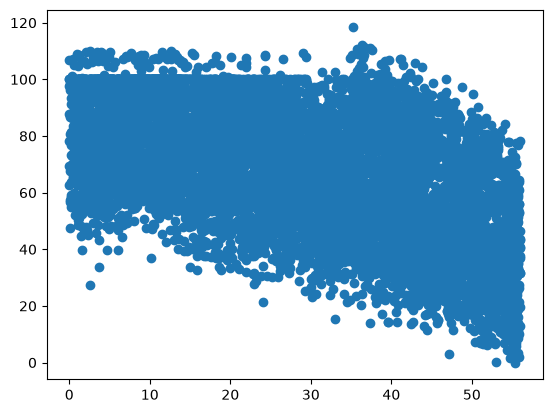

In [19]:
plt.scatter(data["gaming_hours_week"], data["grades"])

plt.show()

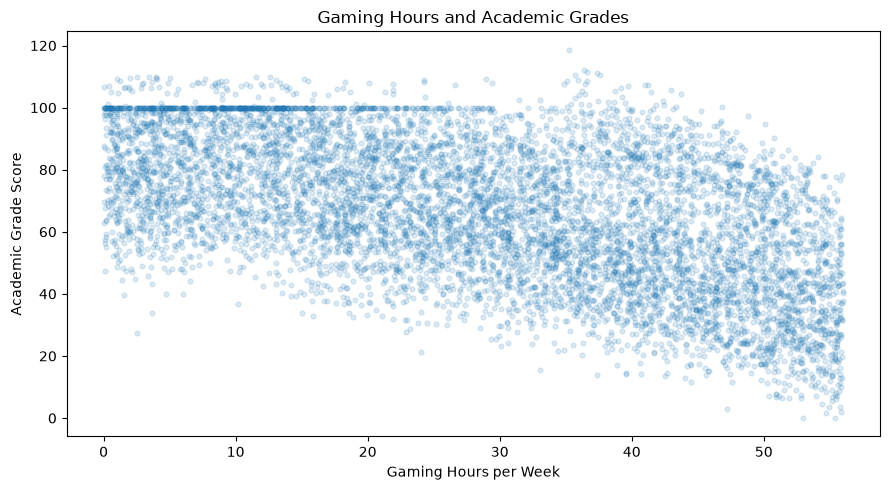

In [20]:
plt.figure(figsize=(9, 5))

plt.scatter(
    data["gaming_hours_week"],
    data["grades"],
    s=12,
    alpha=0.15
)

plt.title("Gaming Hours and Academic Grades")
plt.xlabel("Gaming Hours per Week")
plt.ylabel("Academic Grade Score")

plt.tight_layout()
plt.show()

# I feel that the plot is not particularly readable. To remedy this, I will do the following:
-	Visualize the data in a hexbin for an interesting visualization that makes sense. 
-	I will confirm the data with a regular box plot after. 

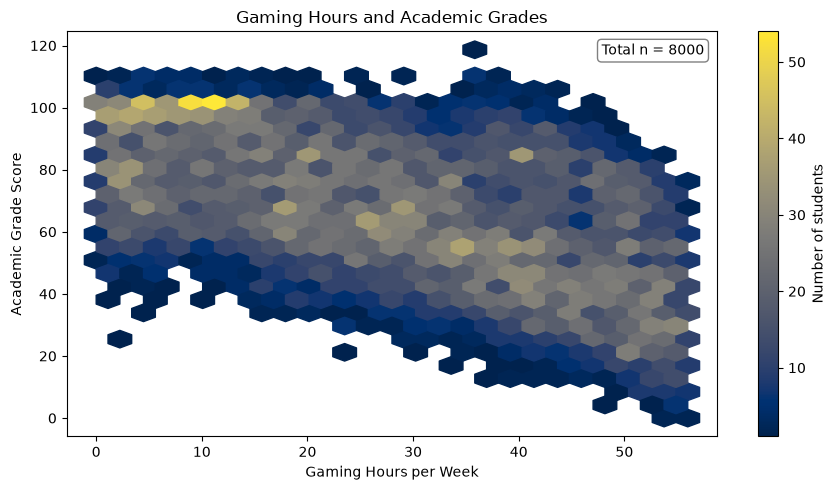

In [41]:
plt.figure(figsize=(9, 5))

hb = plt.hexbin(
    data["gaming_hours_week"],
    data["grades"],
    gridsize=25,
    cmap="cividis",
    mincnt=1
)

cb = plt.colorbar(hb)
cb.set_label("Number of students")

plt.title("Gaming Hours and Academic Grades")
plt.xlabel("Gaming Hours per Week")
plt.ylabel("Academic Grade Score")

# Add total sample size to the graph
plt.text(
    0.98, 0.97,
    f"Total n = {len(data)}",
    transform=plt.gca().transAxes,
    ha="right",
    va="top",
    bbox=dict(facecolor="white", edgecolor="gray", boxstyle="round,pad=0.3")
)

plt.tight_layout()
plt.show()


In [44]:
# Defining gaming-hour groups as easy intervals to interpret and analyze
bins = [0, 10, 20, 30, 40, 60]

labels = ["0-10", "10-20", "20-30", "30-40", "40-60"]

# Assign students to groups
data["gaming_group"] = pd.cut(
    data["gaming_hours_week"],
    bins=bins,
    labels=labels,
    right=False
)


In [46]:
# creating the groups
groups = [
    data.loc[data["gaming_group"] == label, "grades"]
    for label in labels
]

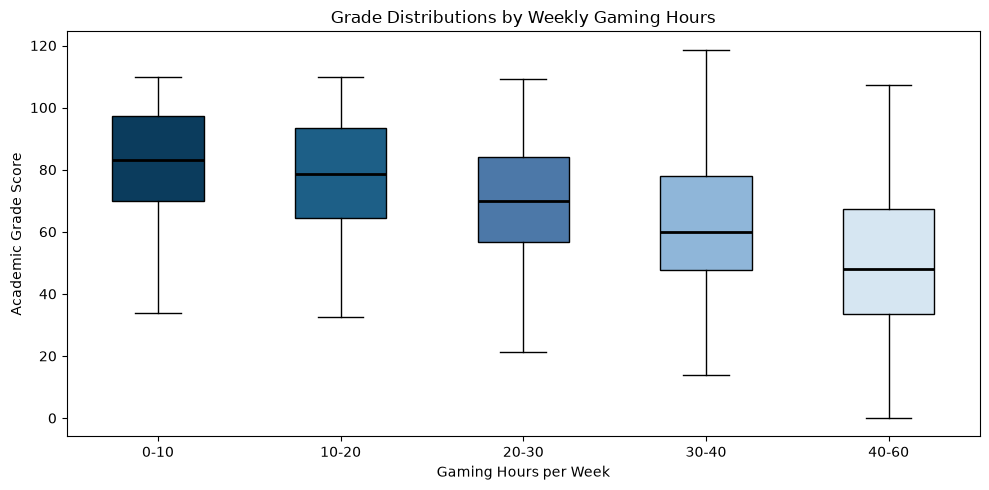

In [52]:
plt.figure(figsize=(10, 5))

box = plt.boxplot(
    groups,
    patch_artist=True,
   tick_labels=labels,
    showfliers=False,
    medianprops={"color": "black", "linewidth": 2}
)

# Dark-to-light blue gradient for better visualisation for those who are color blind
box_colors = ["#0B3C5D", "#1D5F87", "#4C78A8", "#8FB6D9", "#D6E6F2"]

for patch, color in zip(box["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_edgecolor("black")

plt.title("Grade Distributions by Weekly Gaming Hours")
plt.xlabel("Gaming Hours per Week")
plt.ylabel("Academic Grade Score")

plt.tight_layout()
plt.show()